# Estimating common modes

The couplings and the spectrum of a common mode are rarely known in advance.
{func}`~pysanepic.estimate_noise` estimates them from the residual of a first
map: for each {class}`~pysanepic.DetectorGroup` it averages the cross-spectra
of its detectors over all the groups with the same detectors (here the
"days" of a wafer) and fits $R(f) = A\,P(f)\,A^T + \mathrm{diag}\,N(f)$, with
$A$ the couplings, $P$ the spectrum of the mode and $N$ the own noise of each
detector, by expectation-maximization (the spectral matching of `sanePS` in
the IAS version of SANEPIC).

Here: 8 detectors in 4 orthogonal pairs, as on a LiteBIRD wafer, 6 "days";
own 1/f noise plus a common mode with about half of the noise variance,
couplings between 0.6 and 0.8.

In [1]:
import dataclasses

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from pysanepic import CommonMode, DetectorData, DetectorGroup, GLSParameters, OneOverFNoise, Pointing, estimate_noise, make_maps

nside, fs, day = 16, 10.0, 36000  # a "day" of 1 hour, to keep the notebook fast
rng = np.random.default_rng(5)
sky = hp.smoothing(rng.normal(0, 1e-4, (3, 12 * nside**2)), fwhm=np.radians(6))
own = OneOverFNoise(net_ukrts=35.0, fknee_hz=0.05, alpha=1.0, fmin_hz=1e-4)
mode = OneOverFNoise(net_ukrts=50.0, fknee_hz=0.1, alpha=1.5, fmin_hz=1e-4)
coupling = rng.uniform(0.6, 0.8, 8)


def draw(noise, n):
    return np.fft.irfft(np.fft.rfft(rng.normal(size=n)) / np.sqrt(noise.weights(n, fs)), n=n)


def scan(n):
    t = np.arange(n)
    lam = 2 * np.pi * t / n + rng.uniform(0, 2 * np.pi)
    spin = 2 * np.pi * t / 3000.0
    a = np.array([np.cos(lam), np.sin(lam), np.zeros(n)])
    z = np.array([np.zeros(n), np.zeros(n), np.ones(n)])
    e2 = np.cross(a.T, z.T).T
    b = np.cos(1.3) * a + np.sin(1.3) * (np.cos(spin) * z + np.sin(spin) * e2)
    return np.arccos(np.clip(b[2], -1, 1)), np.arctan2(b[1], b[0]) % (2 * np.pi), (spin + lam) % (2 * np.pi)


groups = []
for _ in range(6):
    c = draw(mode, day)
    scans = [scan(day) for _ in range(4)]  # one pointing per pair
    dets = []
    for i in range(8):
        th, ph, psi = scans[i // 2]
        pa = (0.0, np.pi / 2, np.pi / 4, 3 * np.pi / 4)[i % 4]
        a, p = psi + pa, hp.ang2pix(nside, th, ph)
        tod = sky[0, p] + sky[1, p] * np.cos(2 * a) + sky[2, p] * np.sin(2 * a) + draw(own, day) + coupling[i] * c
        dets.append(DetectorData(tod=tod, pointing=Pointing(theta=th, phi=ph, psi=psi, coordinates="E"),
                                 sampling_rate_hz=fs, noise=own, pol_angle_rad=pa, name=f"d{i}"))
    groups.append(DetectorGroup(detectors=dets, modes=[CommonMode(coupling=coupling, noise=mode)]))
names = tuple(d.name for d in groups[0].detectors)

A first map ignoring the correlation (each detector with its own noise
model), then the estimate from its residual.

In [2]:
params = GLSParameters(chunk_s=day / fs, tol=1e-10, coarse_nside=1)
first = make_maps([d for g in groups for d in g.detectors], nside, coordinates="E", params=params)
est = estimate_noise(groups, first, chunk_s=day / fs, nbins=30)
(cm,) = est[names]
scale = np.sqrt(np.mean(coupling**2))  # the estimated couplings have rms 1
print("estimated / true coupling:", np.round(cm.coupling * scale / coupling, 3))

estimated / true coupling: [1.    0.998 1.006 0.998 1.001 0.998 1.003 0.996]


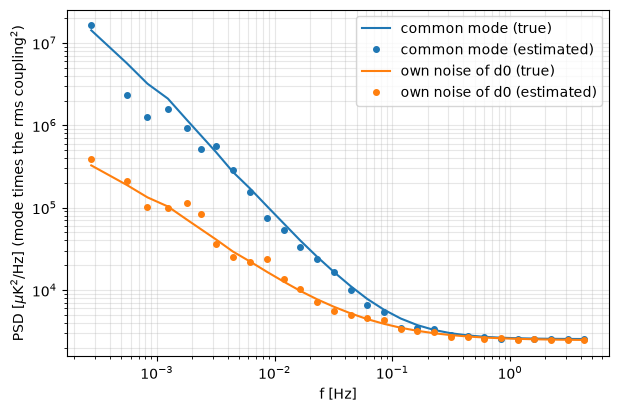

In [3]:
f = cm.noise.freqs_hz


def psd(noise):
    """One-sided PSD [uK^2/Hz] of a OneOverFNoise or TabulatedNoise at f."""
    k = np.round(f * day / fs).astype(int)
    return 2 / (fs * noise.weights(day, fs)[k]) * 1e12


fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(f, psd(mode) * scale**2, "C0", label="common mode (true)")
ax.loglog(f, psd(cm.noise), "C0o", ms=4, label="common mode (estimated)")
ax.loglog(f, psd(own), "C1", label="own noise of d0 (true)")
ax.loglog(f, psd(est["d0"]), "C1o", ms=4, label="own noise of d0 (estimated)")
ax.set_xlabel("f [Hz]")
ax.set_ylabel(r"PSD [$\mu$K$^2$/Hz] (mode times the rms coupling$^2$)")
ax.legend()
ax.grid(alpha=0.3, which="both")

The spectra are found where there are many Fourier modes per bin; at the
lowest frequencies, with 6 hours of data, the estimate is noisy. Then the maps
with the estimated model, compared with the true model and with the
correlation ignored:

In [4]:
estimated = [DetectorGroup(detectors=[dataclasses.replace(d, noise=est[d.name]) for d in g.detectors], modes=est[names])
             for g in groups]
for name, r in (("correlation ignored", first),
                ("true common mode", make_maps(groups, nside, coordinates="E", params=params)),
                ("estimated common mode", make_maps(estimated, nside, coordinates="E", params=params))):
    seen = r.maps[1] != hp.UNSEEN
    err = (r.maps - sky)[:, seen] * 1e6
    print(f"{name:22s} {r.iterations:3d} iterations, rms error I/Q/U {err[0].std():6.2f} / {err[1].std():6.2f} / {err[2].std():6.2f} uK")

correlation ignored     20 iterations, rms error I/Q/U  17.56 /  10.50 /  10.96 uK
true common mode        41 iterations, rms error I/Q/U   9.10 /  10.52 /  10.90 uK
estimated common mode   42 iterations, rms error I/Q/U   9.01 /  10.56 /  10.89 uK


The common mode is the same in the two detectors of a pair, so it cancels in
Q/U and only the I map improves; the map with the estimated mode is as good
as the one with the true mode. On G100 (16 days, 8 detectors, nside 512, half
of the noise variance in the mode) the couplings were found within 0.1% and
the I map with the estimate differed from the one with the true model by 1%
of its noise. One iteration (first map, estimate, map) is enough.